# Where should symmetry go?
## Architecture × coupling in flow matching on DW4

A from-scratch implementation of equivariant flow matching, with a **2 × 3 ablation**:
EGNN vs. parameter-matched MLP; independent, minibatch OT and equivariant OT couplings.

**Two questions:** Does architectural symmetry improve learned sample quality? Can coupling reduce the integration budget needed for a given quality?

This notebook reads saved results only: **no training, model weights or dataset download required**. Outputs are saved for viewing on GitHub.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "results"
ARCHS = ["egnn", "mlp"]
COUPLINGS = ["independent", "ot", "eq_ot"]
LABELS = {"independent": "Independent", "ot": "OT", "eq_ot": "Equivariant OT"}
runs = {(a, c): json.loads((RESULTS / f"{a}_{c}" / "metrics.json").read_text())
        for a in ARCHS for c in COUPLINGS}
assert all(m["epochs"] == 400 and m["n_train"] == 100_000 for m in runs.values())
print("Loaded all 6 completed runs: 400 epochs, 100,000 training configurations each.")

Loaded all 6 completed runs: 400 epochs, 100,000 training configurations each.


### Protocol and metrics

Training seed **0**, batch size **256**, Adam, **400 epochs**, learning rate **5e-4 → 5e-5** at epoch 200; Gaussian path noise σ = **0.01**. EGNN has **25,510** parameters; MLP **25,496**. All configurations are centered.

Evaluation uses **10,000** held-out configurations and a shared prior seed **1234**. Adaptive **dopri5** uses atol = rtol = **1e-5**. Euler uses the saved grid **1, 2, 4, 8, 16, 32, 64, 128**; each step costs one vector-field evaluation.

**W₁** denotes the one-dimensional Wasserstein distance between generated and reference energy (or pooled interparticle-distance) distributions. Lower is better. It is not a percentage or a distance between full configuration distributions. Validation and final evaluation use the same held-out set.

In [2]:
rows = ["| Architecture | Coupling | Energy W₁ (dopri5) | Distance W₁ | Flow equivariance error |",
        "|---|---|---:|---:|---:|"]
for a in ARCHS:
    for c in COUPLINGS:
        m = runs[a, c]
        rows.append(f"| {a.upper()} | {LABELS[c]} | {m['energy_w1']:.3f} | "
                    f"{m['distance_w1']:.3f} | {m['equivariance_error']:.1e} |")
display(Markdown("\n".join(rows)))

| Architecture | Coupling | Energy W₁ (dopri5) | Distance W₁ | Flow equivariance error |
|---|---|---:|---:|---:|
| EGNN | Independent | 0.070 | 0.008 | 3.7e-07 |
| EGNN | OT | 0.075 | 0.010 | 2.8e-07 |
| EGNN | Equivariant OT | 0.256 | 0.013 | 3.1e-07 |
| MLP | Independent | 10.811 | 0.228 | 2.9e-01 |
| MLP | OT | 8.276 | 0.187 | 3.0e-01 |
| MLP | Equivariant OT | 6.364 | 0.158 | 9.1e-02 |

### 1. Architectural symmetry is the dominant effect in this run

With adaptive integration, all EGNN variants have much lower energy and distance errors than the parameter-matched MLP variants. EGNN flow-map equivariance error is approximately **3 × 10⁻⁷**; equivariant coupling reduces the MLP error but does not impose exact symmetry.

The distributions below illustrate the same result. The energy plot clips the right tail into the last bin; the numerical W₁ values above use the unmodified energies.

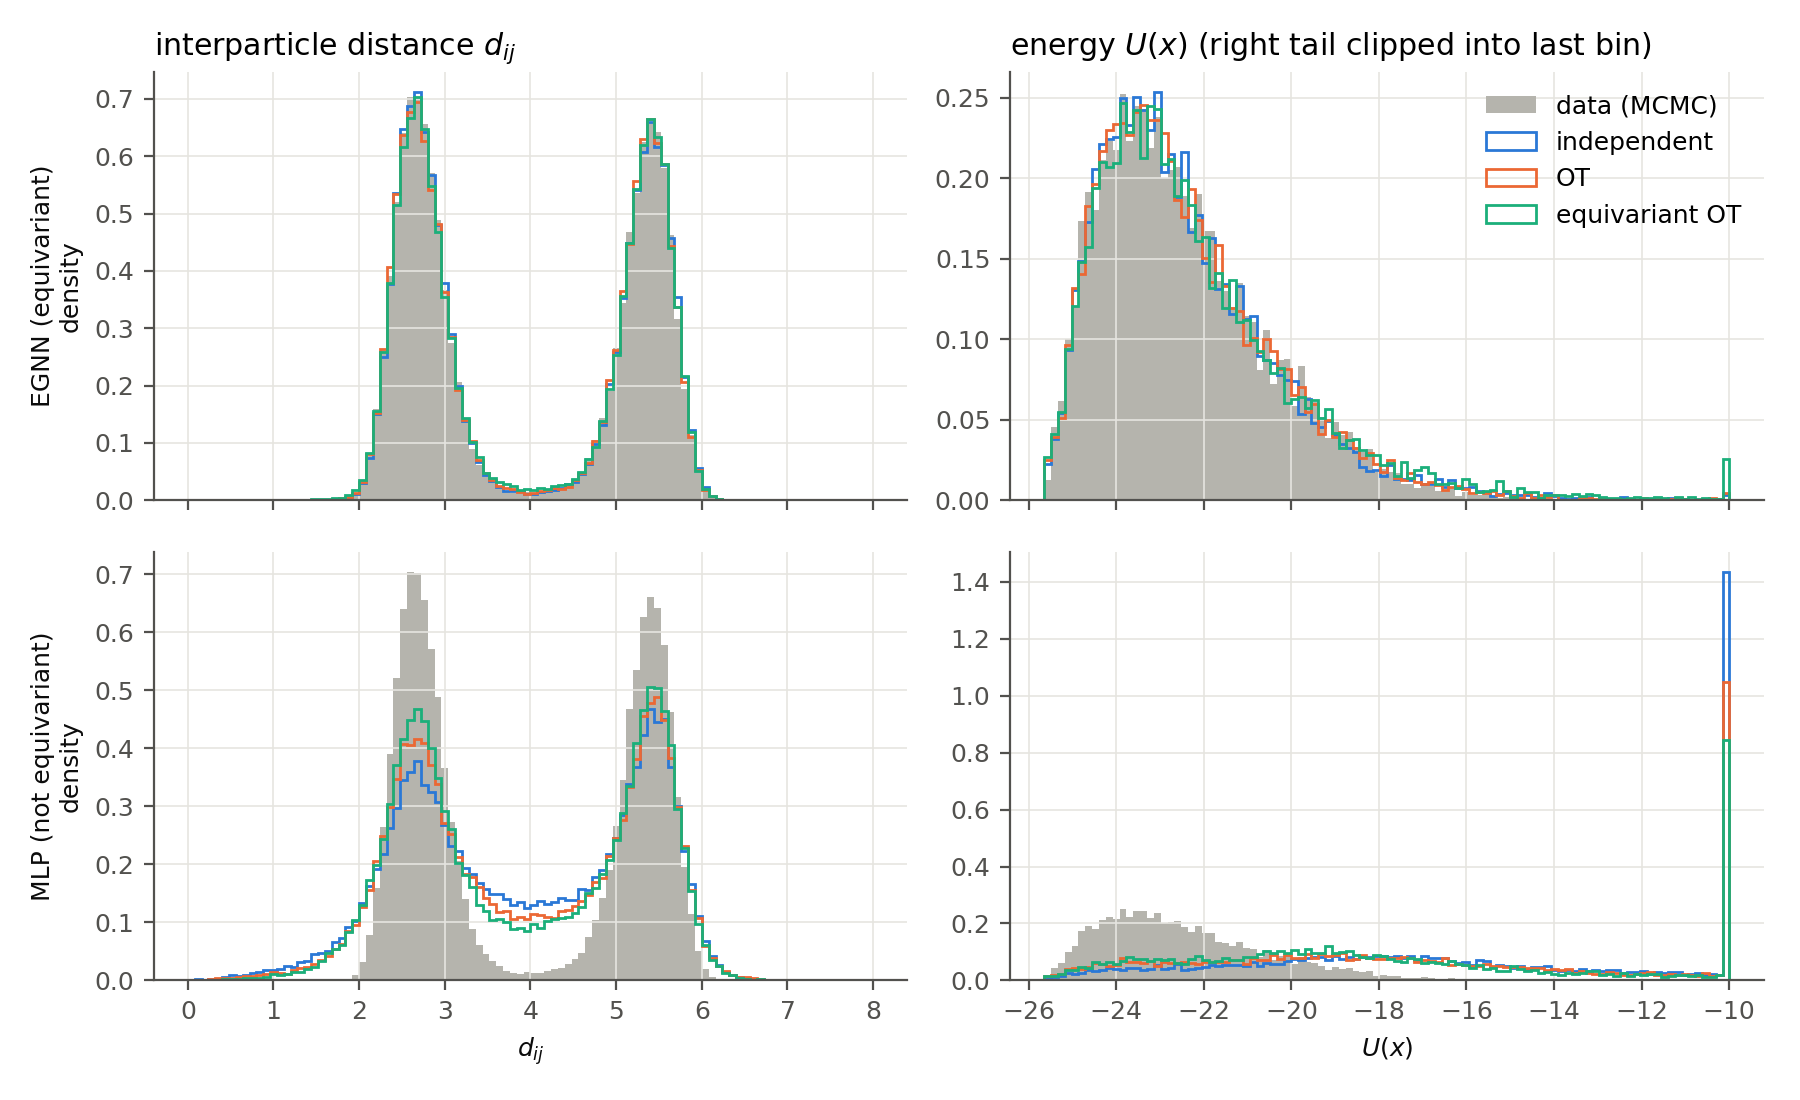

In [3]:
display(Image(filename=str(RESULTS / "fig_distributions.png"), width=900))

### 2. Coupling changes the quality–integration-budget trade-off

Coupling changes the regression paths used in training. Its practical motivation here is easier numerical integration, not an unconditional improvement in final sample quality. Compare **quality at equal Euler steps**, or **tested steps to the same quality target**.

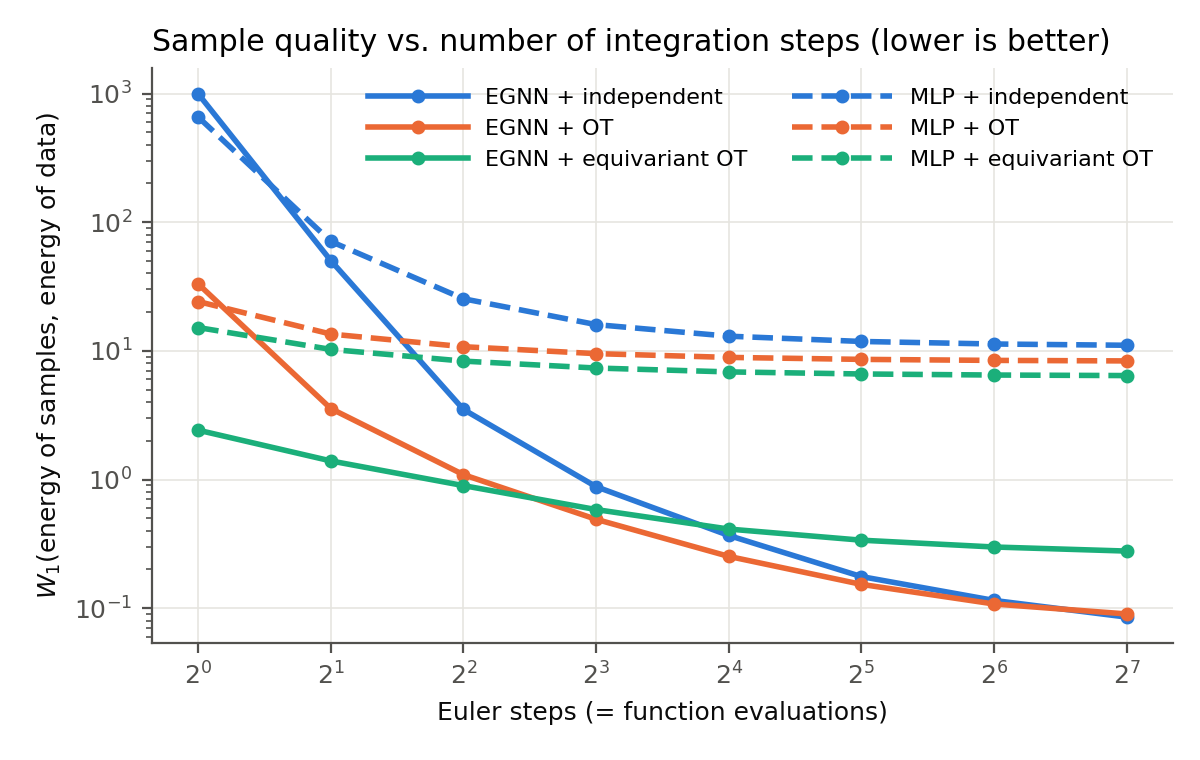

| EGNN coupling | Energy W₁ at 4 steps | First tested steps with W₁ ≤ 0.5 |
|---|---:|---:|
| Independent | 3.506 | 16 |
| OT | 1.091 | 8 |
| Equivariant OT | 0.897 | 16 |

In [4]:
display(Image(filename=str(RESULTS / "fig_nfe.png"), width=800))
rows = ["| EGNN coupling | Energy W₁ at 4 steps | First tested steps with W₁ ≤ 0.5 |",
        "|---|---:|---:|"]
for c in COUPLINGS:
    m = runs["egnn", c]
    curve = {int(k): v for k, v in m["euler_energy_w1"].items()}
    reached = [n for n, error in sorted(curve.items()) if error <= 0.5]
    rows.append(f"| {LABELS[c]} | {curve[4]:.3f} | {min(reached) if reached else 'Not reached'} |")
display(Markdown("\n".join(rows)))

At **4 Euler steps**, ordinary OT reduces EGNN energy W₁ from **3.51 to 1.09**; equivariant OT reaches **0.90**. At the illustrative target **W₁ ≤ 0.5**, ordinary OT reaches the target in **8 tested steps**, versus **16** for independent coupling: half the vector-field evaluations on this grid. These are grid-based comparisons, not exact minimum step counts or wall-clock speedups.

**The benefit depends on the budget:** equivariant OT is strongest at 1–4 steps, but ordinary OT is better at 8–64 steps. With adaptive integration, equivariant OT has a larger error (**0.256**) than independent coupling (**0.070**). Thus, the result supports a low-budget integration benefit, not universal sample-quality superiority.

### Takeaway and scope

**At four Euler steps, this single-seed DW4 ablation showed a larger benefit from equivariant architecture than equivariant OT coupling.** Replacing MLP with EGNN under independent coupling reduces energy W₁ from **25.41 to 3.51**, whereas adding equivariant OT to MLP reduces it from **25.41 to 8.32**. Combining EGNN and equivariant OT gives the lowest error at this budget (**0.90**). This comparison is specific to the chosen integration budget; coupling improves the quality–integration-budget trade-off at low step counts.

One dataset and one training seed; no uncertainty estimates. Equivariant OT cycles through **10 fixed pair sets**, whereas the other modes use fresh noise, so coupling and pair-refresh effects are not isolated. The implementation aligns permutations and then rotations sequentially. Energy and distance marginals are useful diagnostics, not proof of full distributional agreement.

Trajectory straightness is **not measured** here: the saved `path_length` is endpoint displacement, so it is deliberately omitted. Lower Euler error is consistent with easier integration but does not by itself identify trajectory curvature as the cause.

Reference: L. Klein, A. Krämer, F. Noé. *Equivariant flow matching*, NeurIPS 2023. [arXiv:2306.15030](https://arxiv.org/abs/2306.15030).